# Do Chicago Neighborhoods with More Sanitation Complaints Have Worse Food Inspections?
### A ZIP-code analysis of 311 sanitation complaints and CDPH food inspections, 2011–2025

**BA780 · Cohort B · Team 03 · Final Project**

**Data:** City of Chicago Data Portal: *Food Inspections* (Chicago Department of Public Health) and *311 Service Requests: Sanitation Code Complaints*, distributed as five ZIP archives in the [team repository](https://github.com/idanm-commiting/Sanitation-Project). The notebook downloads them automatically into `data/` on first run.

## Executive summary

**Objective.** Test whether the parts of Chicago that generate the most 311 sanitation complaints (garbage, rodents, dumping) also have worse food-inspection results, and turn the answer into a way to target inspections and outreach.

**Method.** We cleaned and stacked **244,005 pass/fail food inspections** and **245,373 de-duplicated sanitation complaints** from 2011–2025 and aggregated both to **57 ZIP codes**. These ZIPs cover 98% of inspections and 95% of complaints. We then measured correlation, compared complaint quartiles, broke results down by risk category and inspection purpose, repeated the test for every year, and ran a within-ZIP panel test.

**Key findings**
1. **Strong ZIP-level link.** ZIPs with more complaints fail more inspections (Pearson r = 0.56) and are cited more often for pests or garbage (r = 0.57). Both are significant at p < 0.001.
2. **Clear dose-response.** From the quarter of ZIPs with the fewest complaints to the quarter with the most, the fail rate rises from **18.1% to 24.7%** and pest/garbage citations rise from **17.5% to 28.0%**.
3. **The gap is about building cleanliness and condition.** The violations that differ most are physical facilities (+16.0 pts), clean food-contact surfaces (+10.9), toilet facilities (+8.2) and insects/rodents (+7.7).
4. **It survives every robustness check.** The gap appears within every risk category, within every inspection purpose, and in every single year from 2011 to 2025.
5. **It is a *where* signal, not a *when* signal.** Within the same ZIP, years with more complaints than usual are *not* worse inspection years (p = 0.64). The link reflects lasting neighborhood conditions, not short-term spikes.
6. **The burden is concentrated.** Twelve South and West Side ZIPs (led by 60619, 60628 and 60620) generate 39% of complaints but only 20% of inspections, and fail 27.6% of inspections versus 22.4% citywide.

**Recommendations.** (1) Use multi-year complaint volume as a standing input to the inspection schedule, prioritizing routine canvass visits in the 12 priority ZIPs. (2) Pair CDPH food-safety outreach with Streets & Sanitation rodent and garbage programs in those same ZIPs. (3) Before reallocating resources, add population and income denominators to separate real conditions from differences in reporting behavior.

## Contents
1. Introduction and motivation
2. Project proposal and data sources
3. Team Assignment recap
4. Data loading and preparation
5. Team Assignment charts, refreshed (Figures 1–5)
6. Is there a ZIP-level relationship? (Figures 6–8)
7. Is the link specific to sanitation? (Figures 9–10)
8. Does it survive robustness checks? (Figures 11–14)
9. Where should the city act first? (Figure 15)
10. Conclusion and recommendations
11. Challenges
12. References
13. Generative AI disclosure

## 1. Introduction and motivation

Chicago watches the cleanliness of its neighborhoods through two systems that never talk to each other. Residents file roughly **16,000 sanitation complaints a year** through 311 about overflowing carts, rodents and illegal dumping. Separately, CDPH inspectors complete about **16,000 pass/fail food inspections a year**, and more than one in five fail.

If the two signals line up, the city has a free, continuously updated indicator of where food-safety problems are likely to be. Inspectors could use it to pick which areas to canvass first, and the departments could coordinate pest-control and food-safety outreach. If the signals do *not* line up, using complaints this way would misdirect scarce inspectors.

**Why read this analysis:** it answers a practical targeting question with data the city already publishes. It also shows what the complaint signal can and cannot be used for, which matters as much as the headline correlation.

## 2. Project proposal and data sources

**Problem statement.** Do Chicago ZIP codes with more 311 sanitation complaints have worse food-inspection outcomes, and if so, where should the city focus?

| Section | Question of interest |
|---|---|
| 6 | Is complaint volume associated with inspection failure across ZIP codes? How strong is the association, and where is it concentrated? |
| 7 | Is the association specific to sanitation-type violations (pests, garbage, facility cleanliness)? |
| 8 | Does it survive differences in risk mix and inspection purpose, and does it hold over time and within a ZIP? |
| 9 | Which ZIP codes should be prioritized? |

| Dataset | Publisher | Unit of observation | Raw rows | Key fields used |
|---|---|---|---|---|
| [Food Inspections](https://data.cityofchicago.org/Health-Human-Services/Food-Inspections/4ijn-s7e5) | Chicago Dept. of Public Health | One inspection of one establishment | 315,488 | Inspection ID, Results, Risk, Inspection Type, Violations, Zip, Latitude/Longitude, Inspection Date |
| [311 Sanitation Code Complaints](https://data.cityofchicago.org/Service-Requests/311-Service-Requests-Sanitation-Code-Complaints-Hi/me59-5fac) (historical + current, combined by the team) | City of Chicago 311 | One resident service request | 266,702 | Request Number, Status, ZIP Code, Latitude/Longitude, Created Date |

**Approach.** We stack (concatenate) both sources into one table, clean each record type, and aggregate both to **ZIP code**. ZIP is the finest geography that both datasets record reliably: the inspection data has no ward or community-area field, and street addresses rarely match between the two (see Section 4). All rates are computed on full calendar years, 2011–2025.

## 3. Team Assignment recap

In the Team Assignment ([`B03-Chicago-Food-Inspection-And-Sanitation.ipynb`](B03-Chicago-Food-Inspection-And-Sanitation.ipynb)) we profiled each dataset **separately** and deliberately did not link them. Key results:

- **Cleaning.** We removed 7,272 complaints the city had marked as duplicates and 807 repeated request numbers, and excluded non-outcome inspection results (*No Entry*, *Out of Business*, ...) from fail-rate denominators.
- **Complaints.** Volume peaked in 2016 (19,970) and bottomed in 2019 (12,260). The ten busiest ZIPs held 36% of complaints, led by 60620. Community area 25 and ward 6 led the other geographic rankings.
- **Inspections.** 23.0% of 2019–2025 inspections failed. *Low*-risk establishments failed more often than *High*-risk ones (25.9% vs. 22.9%). Long-term-care facilities had the highest fail rate among common facility types, and violation code 55 (physical facilities) was the most frequent finding among failures.
- **Open question carried forward:** *do the complaint hot spots and the inspection results line up?* This final phase answers it.

Figures 1–5 below refresh the Team Assignment charts on the 2011–2025 window. We replaced the community-area and ward rankings with two inspection-side charts (fail rate by year and by risk category). The final question is ZIP-based and needs both datasets in view.

## 4. Data loading and preparation

### 4.1 Load and stack the two sources
The loader downloads each archive once, caches it in `data/`, and renames the shared fields (`Street Address`, `ZIP Code`, `Record Date`) so the two record types line up. We then **concatenate** them into one long table, `combined_df`, and use `Record Type` to tell them apart.

**Why concatenate instead of merging on address?** An earlier version joined inspections to complaints on exact street address and year. Only about 1% of complaints matched, for two reasons:
- Most sanitation complaints are filed at homes, not restaurants.
- Address formats differ between the datasets (`5024 S Wolcott (1900W)` vs. `5024 S WOLCOTT AVE`).

The join also duplicated an inspection row for every matching complaint. Stacking the records and aggregating each type to ZIP avoids both problems.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile, is_zipfile
import shutil
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MultipleLocator, PercentFormatter, StrMethodFormatter
from scipy import stats
from IPython.display import display

BASE_URL = "https://raw.githubusercontent.com/idanm-commiting/Sanitation-Project/main/"
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
FOOD_FILES = ["Food_Inspections_part_1.zip", "Food_Inspections_part_2a.zip",
              "Food_Inspections_part_2b.zip", "Food_Inspections_part_3.zip"]
COMPLAINT_FILE = "311_Sanitation_Combined_2010_2026.zip"


def load_github_zip(filename, record_type):
    """Download and cache a ZIP, then read all CSV members without extracting."""
    archive_path = DATA_DIR / filename
    if not archive_path.exists() or not is_zipfile(archive_path):
        print(f"Downloading {filename} ...", flush=True)
        temporary_path = archive_path.with_suffix(".zip.part")
        with urlopen(BASE_URL + filename, timeout=120) as response:
            with temporary_path.open("wb") as destination:
                shutil.copyfileobj(response, destination)
        if not is_zipfile(temporary_path):
            raise ValueError(f"The download for {filename} is not a valid ZIP file.")
        temporary_path.replace(archive_path)

    frames = []
    with ZipFile(archive_path) as archive:
        csv_members = [
            name for name in archive.namelist()
            if name.lower().endswith(".csv") and not name.startswith("__MACOSX/")
        ]
        if not csv_members:
            raise ValueError(f"No CSV files found in {filename}.")
        for member in csv_members:
            with archive.open(member) as csv_file:
                frame = pd.read_csv(csv_file, low_memory=False)
            frame.columns = frame.columns.str.strip()
            # Align shared fields before stacking the two kinds of records.
            frame = frame.rename(columns={
                "Created Date": "Creation Date",
                "Address": "Street Address",
                "Zip": "ZIP Code",
            })
            date_column = "Creation Date" if record_type == "311 complaint" else "Inspection Date"
            frame["Record Date"] = pd.to_datetime(
                frame[date_column], errors="coerce", format="mixed"
            )
            frame["Record Type"] = record_type
            frame["Source File"] = filename
            frames.append(frame)
    return pd.concat(frames, ignore_index=True, sort=False)


df_food = pd.concat(
    [load_github_zip(f, "Food inspection") for f in FOOD_FILES], ignore_index=True, sort=False
)
df_311 = load_github_zip(COMPLAINT_FILE, "311 complaint")

# Stack both sources into one long table. Shared fields (Street Address, ZIP Code,
# Latitude/Longitude, Record Date) line up; "Record Type" tells the two apart.
combined_df = pd.concat([df_food, df_311], ignore_index=True, sort=False)
combined_df["Year"] = combined_df["Record Date"].dt.year

display(combined_df.groupby("Record Type").agg(
    rows=("Record Type", "size"),
    first_record=("Record Date", "min"),
    last_record=("Record Date", "max"),
))

,rows,first_record,last_record
Record Type,,,
311 complaint,266702,2010-01-24,2026-09-24 00:05:38
Food inspection,315488,2010-01-04,2026-09-14 00:00:00


In [2]:
# One look for every chart: seaborn's white-grid theme, blue for single-series charts,
# and a light-to-dark blue palette for the four complaint quartiles (Q1 = fewest complaints).
sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "grid.color": "#e1e0d9", "legend.frameon": False,
})
BLUE, ORANGE, RED, GRAY, LIGHT_GRAY = "#2a78d6", "#eb6834", "#e34948", "#52514e", "#c3c2b7"
QUARTILE_PALETTE = {"Q1": "#86b6ef", "Q2": "#3987e5", "Q3": "#256abf", "Q4": "#104281"}
pd.set_option("display.max_columns", 12)

### 4.2 Clean each record type

| Issue | Decision | Why |
|---|---|---|
| Repeated IDs | Keep one row per `Inspection ID` / `Request Number` | Count each event once |
| Complaints marked "Dup" by the city | Drop | They are not independent complaints |
| Non-outcome results (*No Entry*, *Out of Business*, *Not Ready*, ...) | Exclude from rates | No pass/fail decision was made |
| Partial years (2010 complaints are sparse; 2026 is incomplete) | Keep 2011–2025 | Compare like-for-like full years |
| ZIP stored as float or with junk values | Normalize to a five-digit string, otherwise `<NA>` | Consistent grouping key |
| Violation codes renumbered by the July 2018 food code | Flag sanitation issues by **keyword** (rodent, insect, roach, mice, pest, garbage, refuse) for all years; compare codes only for 2019–2025 | Keep the measure consistent across eras |
| ~100 spellings of `Inspection Type` | Collapse to five purposes (routine canvass, complaint-driven, license, re-inspection, other) | Needed for the Section 8 robustness check |

In [3]:
YEARS = range(2011, 2026)   # full years only: 2010 complaints are sparse and 2026 is partial
OUTCOMES = ["Pass", "Pass w/ Conditions", "Fail"]
SANITATION_PATTERN = r"RODENT|INSECT|ROACH|MICE|MOUSE|VERMIN|PEST|GARBAGE|REFUSE"

# Inspections: one row per inspection that ended in a pass/fail decision
food_raw = combined_df[combined_df["Record Type"] == "Food inspection"]
food_unique = food_raw.drop_duplicates("Inspection ID")
food_outcomes = food_unique[food_unique["Results"].isin(OUTCOMES)]
inspections = food_outcomes[food_outcomes["Year"].isin(YEARS)].copy()

# Complaints: drop requests the city marked as duplicates, then keep one row per request
calls_raw = combined_df[combined_df["Record Type"] == "311 complaint"]
calls_unique = calls_raw[~calls_raw["Status"].str.contains("Dup", na=False)].drop_duplicates("Request Number")
complaints = calls_unique[calls_unique["Year"].isin(YEARS)].copy()

display(pd.DataFrame({
    "Inspections": {"Raw records": len(food_raw), "Duplicates removed": len(food_unique),
                    "Pass/fail results only": len(food_outcomes), "Years 2011–2025": len(inspections)},
    "Complaints": {"Raw records": len(calls_raw), "Duplicates removed": len(calls_unique),
                   "Years 2011–2025": len(complaints)},
}).astype("Int64"))

# Shared columns: integer year and a five-digit ZIP string (<NA> when missing or invalid)
for frame in [inspections, complaints]:
    frame["Year"] = frame["Year"].astype(int)
    zip_code = pd.to_numeric(frame["ZIP Code"], errors="coerce").astype("Int64").astype("string")
    frame["zip"] = zip_code.where(zip_code.str.fullmatch(r"\d{5}", na=False))

# Inspection columns used by the charts
inspections["failed"] = (inspections["Results"] == "Fail").astype(int)
inspections["sanitation_violation"] = (inspections["Violations"].fillna("").str.upper()
                                       .str.contains(SANITATION_PATTERN).astype(int))
inspections["risk"] = inspections["Risk"].map(
    {"Risk 1 (High)": "High", "Risk 2 (Medium)": "Medium", "Risk 3 (Low)": "Low"})
inspection_type = inspections["Inspection Type"].fillna("").str.lower()
inspections["purpose"] = np.select(
    [inspection_type.str.contains("re-insp|reinsp"), inspection_type.str.contains("complaint"),
     inspection_type.str.contains("canvass"), inspection_type.str.contains("license")],
    ["Re-inspection", "Complaint-driven", "Routine canvass", "License"],
    default="Other",
)

print(f"Unknown ZIP: {inspections['zip'].isna().mean():.2%} of inspections, "
      f"{complaints['zip'].isna().mean():.2%} of complaints")

# Consistency checks: every later figure relies on these
assert inspections["Inspection ID"].is_unique and complaints["Request Number"].is_unique
assert inspections["Results"].isin(OUTCOMES).all()
assert inspections["Year"].between(2011, 2025).all() and complaints["Year"].between(2011, 2025).all()

,Inspections,Complaints
Raw records,315488,266702
Duplicates removed,315488,258623
Pass/fail results only,270847,<NA>
Years 2011–2025,244005,245373


Unknown ZIP: 0.01% of inspections, 4.68% of complaints


**Takeaway:** **244,005** pass/fail inspections and **245,373** complaints remain for 2011–2025. ZIP is missing for only 0.01% of inspections and 4.7% of complaints, so a ZIP-level analysis keeps nearly all of the data.

## 5. Team Assignment charts, refreshed (Figures 1–5)

### 5.1 How has sanitation complaint volume changed over time?

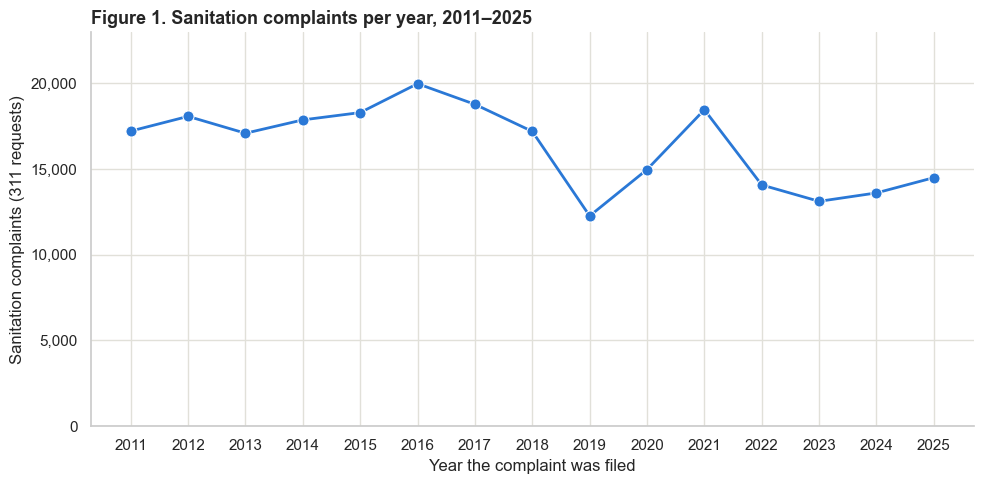

Peak: 2016 (19,970); low: 2019 (12,260); average: 16,358 per year


In [4]:
annual_complaints = complaints["Year"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(x=annual_complaints.index, y=annual_complaints.values, color=BLUE,
             marker="o", markersize=8, linewidth=2, ax=ax)
ax.set_xticks(list(YEARS))
ax.set_ylim(0, annual_complaints.max() * 1.15)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set(xlabel="Year the complaint was filed", ylabel="Sanitation complaints (311 requests)",
       title="Figure 1. Sanitation complaints per year, 2011–2025")
plt.tight_layout()
plt.show()

print(f"Peak: {annual_complaints.idxmax()} ({annual_complaints.max():,}); "
      f"low: {annual_complaints.idxmin()} ({annual_complaints.min():,}); "
      f"average: {annual_complaints.mean():,.0f} per year")

**Answer:** Volume averaged about 16,400 complaints a year. It peaked in 2016 (19,970) and dropped to 12,260 in 2019. The 2019 dip may reflect the city's 311 system transition at the end of 2018 rather than cleaner streets. Because of this, we use *multi-year* totals per ZIP rather than single-year swings to measure complaint burden.

### 5.2 Which ZIP codes generate the most complaints?

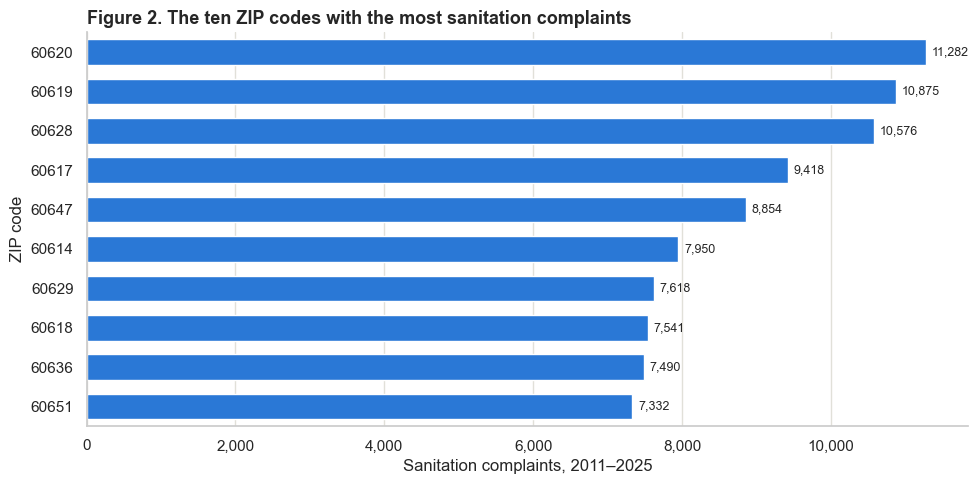

The top ten ZIPs hold 36.2% of all complaints (61 ZIPs appear in the data).


In [5]:
top_zips = complaints["zip"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=top_zips.values, y=top_zips.index.astype(str), color=BLUE, width=0.65, saturation=1, ax=ax)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=4, fontsize=9)
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set(xlabel="Sanitation complaints, 2011–2025", ylabel="ZIP code",
       title="Figure 2. The ten ZIP codes with the most sanitation complaints")
plt.tight_layout()
plt.show()

print(f"The top ten ZIPs hold {top_zips.sum() / len(complaints):.1%} of all complaints "
      f"({complaints['zip'].nunique()} ZIPs appear in the data).")

**Answer:** Complaints are concentrated: the ten busiest ZIPs (of 61) account for 36.2% of all requests. The top three, **60620, 60619 and 60628**, are adjacent Far South Side ZIPs, and they reappear at the top of every later chart.

### 5.3 Where are complaints located on the city map?

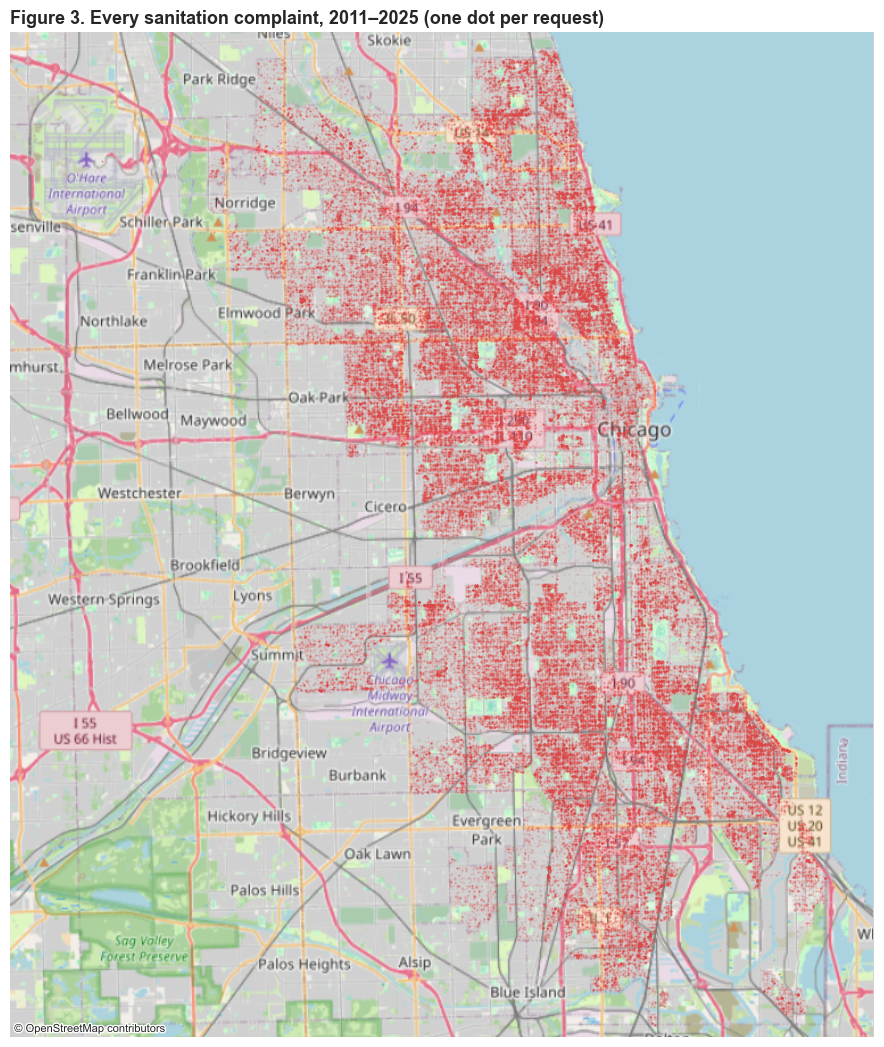

Mapped 245,249 of 245,373 complaints (99.95%).


In [6]:
import contextily as ctx

# Every complaint with coordinates, on an OpenStreetMap basemap (downloaded once, cached in data/)
west, east, south, north = -87.95, -87.50, 41.64, 42.03
points = complaints[complaints["Latitude"].between(south, north) & complaints["Longitude"].between(west, east)]
basemap_path = DATA_DIR / "chicago_osm_z11.tif"
if not basemap_path.exists():
    ctx.bounds2raster(west, south, east, north, str(basemap_path), zoom=11, ll=True,
                      source=ctx.providers.OpenStreetMap.Mapnik)

fig, ax = plt.subplots(figsize=(9, 11))
sns.scatterplot(data=points, x="Longitude", y="Latitude", s=2, color=RED, alpha=0.15,
                linewidth=0, rasterized=True, ax=ax)
ax.set(xlim=(west, east), ylim=(south, north))
ctx.add_basemap(ax, crs="EPSG:4326", source=str(basemap_path),
                attribution="© OpenStreetMap contributors", attribution_size=8)
ax.set_aspect(1 / np.cos(np.radians(41.85)))   # degrees of longitude are shorter at Chicago's latitude
ax.set_axis_off()
ax.set_title("Figure 3. Every sanitation complaint, 2011–2025 (one dot per request)")
plt.tight_layout()
plt.show()

print(f"Mapped {len(points):,} of {len(complaints):,} complaints ({len(points) / len(complaints):.2%}).")

**Answer:** 99.95% of complaints have usable coordinates. They cover nearly the entire city, with the densest coverage across the South and West Sides. The map shows *where* people report, but because dots overlap, it cannot show *how much more* one area reports than another. Section 6 handles that by counting per ZIP.

### 5.4 How has the food-inspection fail rate changed over time?

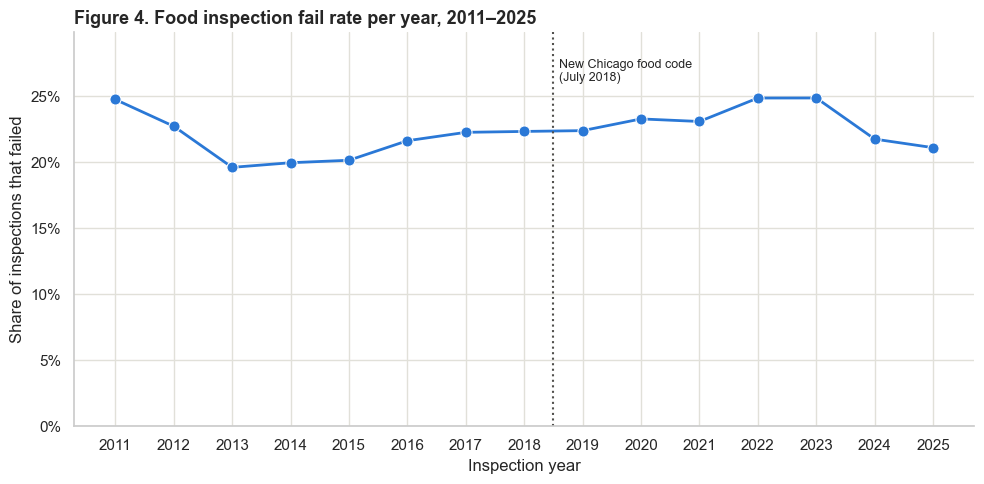

Overall fail rate: 22.2% of 244,005 inspections; range 19.6% (2013) to 24.9% (2023).


In [7]:
annual_fail = inspections.groupby("Year")["failed"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(x=annual_fail.index, y=annual_fail.values, color=BLUE,
             marker="o", markersize=8, linewidth=2, ax=ax)
ax.axvline(2018.5, color=GRAY, linestyle=":", linewidth=1.5)
ax.text(2018.6, annual_fail.max() * 1.12, "New Chicago food code\n(July 2018)", fontsize=9, va="top")
ax.set_xticks(list(YEARS))
ax.set_ylim(0, annual_fail.max() * 1.2)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(xlabel="Inspection year", ylabel="Share of inspections that failed",
       title="Figure 4. Food inspection fail rate per year, 2011–2025")
plt.tight_layout()
plt.show()

print(f"Overall fail rate: {inspections['failed'].mean():.1%} of {len(inspections):,} inspections; "
      f"range {annual_fail.min():.1%} ({annual_fail.idxmin()}) to {annual_fail.max():.1%} ({annual_fail.idxmax()}).")

**Answer:** 22.2% of the 244,005 inspections failed. The yearly rate stayed in a narrow band, from 19.6% (2013) to 24.9% (2023), with no break at the July 2018 food-code change. A stable citywide rate means differences *between* ZIPs are not just artifacts of when inspections happened.

### 5.5 Do higher-risk establishments fail more often?

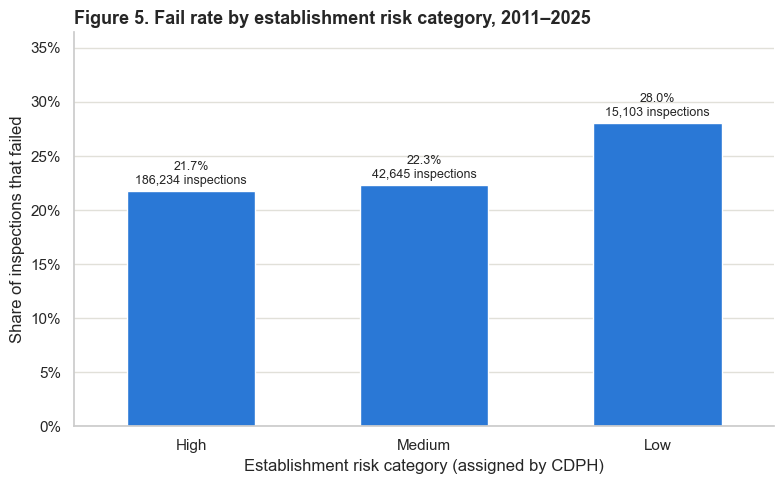

In [8]:
risk_rates = inspections.groupby("risk")["failed"].agg(["mean", "size"]).reindex(["High", "Medium", "Low"])

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=risk_rates.index, y=risk_rates["mean"], color=BLUE, width=0.55, saturation=1, ax=ax)
ax.bar_label(ax.containers[0], padding=3, fontsize=9,
             labels=[f"{rate:.1%}\n{n:,} inspections" for rate, n in zip(risk_rates["mean"], risk_rates["size"])])
ax.set_ylim(0, risk_rates["mean"].max() * 1.3)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(xlabel="Establishment risk category (assigned by CDPH)", ylabel="Share of inspections that failed",
       title="Figure 5. Fail rate by establishment risk category, 2011–2025")
plt.tight_layout()
plt.show()

**Answer:** No. *Low*-risk establishments fail most often (28.0%), compared with 21.7% for *High*-risk ones, which confirms the Team Assignment finding. CDPH's risk category reflects how complex an establishment's food handling is, not how well it complies. Because the risk mix also differs between neighborhoods, Section 8 checks that the complaint relationship is not just a risk-mix effect.

## 6. Is there a ZIP-level relationship? (Figures 6–8)

We build one row per ZIP from each record type, then line the two up with a column-wise concat on the ZIP index. ZIPs with fewer than 200 inspections or 100 complaints over 15 years are dropped because their rates are too noisy. That leaves **57 ZIPs**, covering 97.9% of inspections and 95.3% of complaints.

In [9]:
MIN_INSPECTIONS, MIN_COMPLAINTS = 200, 100   # drop ZIPs too small for a stable rate

zip_inspections = inspections.groupby("zip").agg(
    inspections=("Inspection ID", "size"),
    establishments=("License #", "nunique"),
    fail_rate=("failed", "mean"),
    sanitation_violation_rate=("sanitation_violation", "mean"),
)
zip_complaints = complaints.groupby("zip").size().rename("complaints")

# Both tables have one row per ZIP, so a column-wise concat lines them up on the ZIP index.
zip_df = pd.concat([zip_inspections, zip_complaints], axis=1, join="inner")
zip_df = zip_df[(zip_df["inspections"] >= MIN_INSPECTIONS) & (zip_df["complaints"] >= MIN_COMPLAINTS)].copy()
zip_df["complaints_per_year"] = zip_df["complaints"] / len(YEARS)
zip_df["quartile"] = pd.qcut(zip_df["complaints_per_year"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
inspections["quartile"] = inspections["zip"].map(zip_df["quartile"])

# Pearson correlation of complaints with each inspection rate
rows = []
for measure in ["fail_rate", "sanitation_violation_rate"]:
    r, p_r = stats.pearsonr(zip_df["complaints_per_year"], zip_df[measure])
    rows.append({"Complaints per year vs.": measure, "Pearson r": r, "Pearson p": p_r})
correlations = pd.DataFrame(rows).set_index("Complaints per year vs.")

print(f"{len(zip_df)} ZIP codes kept; they cover {zip_df['inspections'].sum() / len(inspections):.1%} "
      f"of inspections and {zip_df['complaints'].sum() / len(complaints):.1%} of complaints.")
display(correlations.round(4))
display(zip_df.sort_values("complaints", ascending=False).head(3).round(3))

57 ZIP codes kept; they cover 97.9% of inspections and 95.3% of complaints.


,Pearson r,Pearson p
Complaints per year vs.,,
fail_rate,0.5622,0.0
sanitation_violation_rate,0.5665,0.0


,inspections,establishments,fail_rate,sanitation_violation_rate,complaints,complaints_per_year,quartile
zip,,,,,,,
60620,4674,730,0.289,0.356,11282,752.133,Q4
60619,4799,794,0.301,0.368,10875,725.000,Q4
60628,4360,676,0.292,0.371,10576,705.067,Q4


### 6.1 Do ZIP codes with more sanitation complaints fail more food inspections?

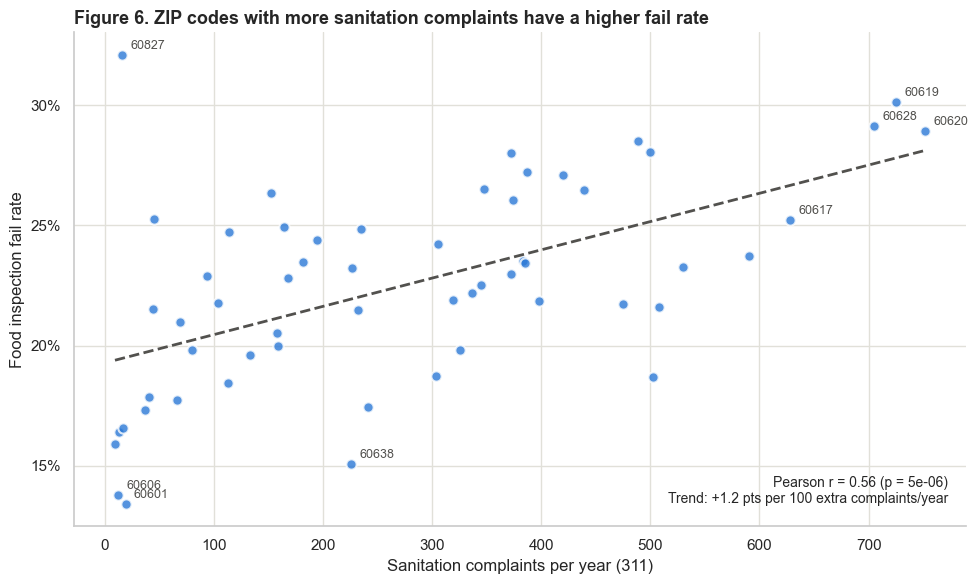

Trend line: 19.3% at zero complaints, +1.18 pts per 100 complaints/year


In [10]:
fit = stats.linregress(zip_df["complaints_per_year"], zip_df["fail_rate"])
corr = correlations.loc["fail_rate"]

fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=zip_df, x="complaints_per_year", y="fail_rate", ci=None, color=BLUE,
            scatter_kws={"s": 55, "edgecolor": "white", "linewidths": 1.5},
            line_kws={"color": GRAY, "linestyle": "--", "linewidth": 2}, ax=ax)

# Label the busiest ZIPs and the ZIPs with the highest and lowest fail rates
labeled = (set(zip_df.nlargest(4, "complaints_per_year").index)
           | set(zip_df.nlargest(3, "fail_rate").index) | set(zip_df.nsmallest(3, "fail_rate").index))
for z in labeled:
    ax.annotate(z, (zip_df.loc[z, "complaints_per_year"], zip_df.loc[z, "fail_rate"]),
                xytext=(6, 4), textcoords="offset points", fontsize=9, color=GRAY)

ax.text(0.98, 0.04,
        f"Pearson r = {corr['Pearson r']:.2f} (p = {corr['Pearson p']:.0e})\n"
        f"Trend: +{fit.slope * 100 * 100:.1f} pts per 100 extra complaints/year",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=10)
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(xlabel="Sanitation complaints per year (311)", ylabel="Food inspection fail rate",
       title="Figure 6. ZIP codes with more sanitation complaints have a higher fail rate")
plt.tight_layout()
plt.show()

print(f"Trend line: {fit.intercept:.1%} at zero complaints, +{fit.slope * 100 * 100:.2f} pts per 100 complaints/year")

**Answer: Yes, moderately strongly.** Across 57 ZIPs, complaint volume and fail rate move together: Pearson r = 0.56, p < 0.001. On the trend line, each additional 100 complaints per year is associated with a fail rate about **1.2 points higher**.

The exceptions are informative:
- **60601 and 60606 (the Loop)** have few complaints and the lowest fail rates.
- **60827** has a high fail rate but few complaints. It straddles the city's southern border, so much of it falls outside Chicago's 311 coverage.

### 6.2 Is there a dose-response pattern, or just a few extreme ZIPs?

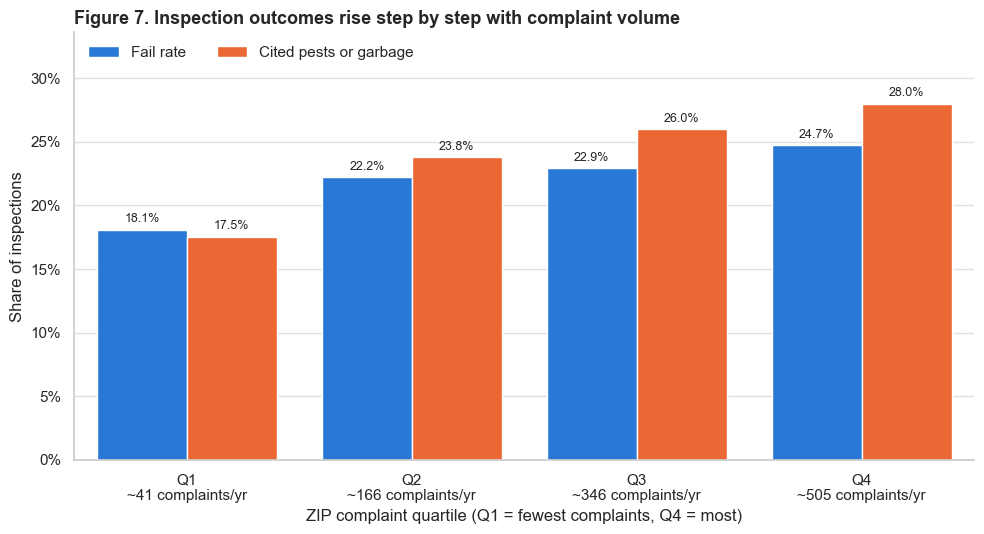

,fail_rate,sanitation_violation_rate,inspections,zips,complaints_per_year
quartile,,,,,
Q1,0.181,0.175,45749,15,40.667
Q2,0.222,0.238,54110,14,166.200
Q3,0.229,0.260,61444,14,346.467
Q4,0.247,0.280,77463,14,505.300


In [11]:
by_quartile = (inspections.dropna(subset=["quartile"])
               .groupby("quartile", observed=True)
               .agg(fail_rate=("failed", "mean"),
                    sanitation_violation_rate=("sanitation_violation", "mean"),
                    inspections=("Inspection ID", "size"),
                    zips=("zip", "nunique")))
by_quartile["complaints_per_year"] = zip_df.groupby("quartile", observed=True)["complaints_per_year"].median()

# Long format: one row per quartile and measure, so seaborn can draw the two measures side by side
plot_data = by_quartile.reset_index().melt(
    id_vars="quartile", value_vars=["fail_rate", "sanitation_violation_rate"],
    var_name="Measure", value_name="Share")
plot_data["Measure"] = plot_data["Measure"].map(
    {"fail_rate": "Fail rate", "sanitation_violation_rate": "Cited pests or garbage"})

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=plot_data, x="quartile", y="Share", hue="Measure", palette=[BLUE, ORANGE], saturation=1, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="{:.1%}", padding=3, fontsize=9)
ax.set_xticks(range(4), [f"{q}\n~{c:,.0f} complaints/yr" for q, c in by_quartile["complaints_per_year"].items()])
ax.set_ylim(0, plot_data["Share"].max() * 1.2)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(loc="upper left", ncols=2, title=None)
ax.set(xlabel="ZIP complaint quartile (Q1 = fewest complaints, Q4 = most)", ylabel="Share of inspections",
       title="Figure 7. Inspection outcomes rise step by step with complaint volume")
plt.tight_layout()
plt.show()

display(by_quartile.round(3))

**Answer: A steady dose-response.** Splitting the 57 ZIPs into four equal groups by complaint volume:
- The **fail rate** climbs at every step: 18.1% → 22.2% → 22.9% → 24.7%. Q4 is **36% higher** than Q1.
- **Pest/garbage citations** climb even faster: 17.5% → 28.0%, **60% higher**.

The pattern holds across the whole range, not just a few outlier ZIPs.

### 6.3 Where are the high-complaint, high-failure ZIP codes?

We split the 57 ZIPs at the median of complaints per year and the median fail rate, which gives four groups (Figure 8a), and then map those groups (Figure 8b). The quadrant chart and map are adapted from the team's Story 3 analysis (`chicago_story1_story3_graft.ipynb`).

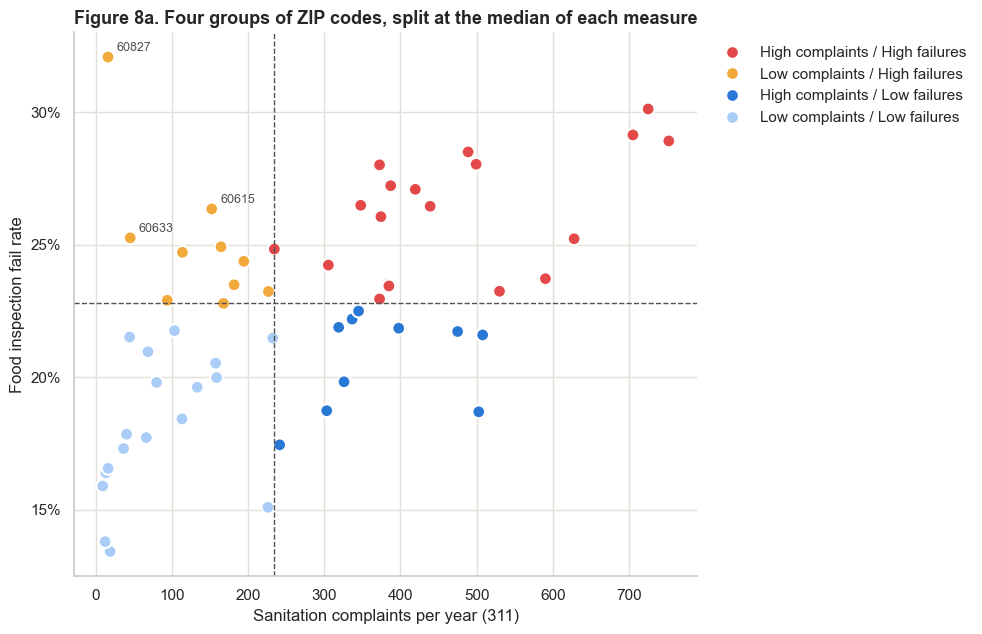

Medians: 235 complaints/year, 22.8% fail rate


,zips,complaints_per_year,fail_rate,sanitation_violation_rate
quadrant,,,,
High complaints / High failures,19,419.533,0.265,0.314
Low complaints / High failures,10,158.467,0.245,0.273
High complaints / Low failures,10,340.867,0.217,0.223
Low complaints / Low failures,18,67.600,0.181,0.188


In [12]:
# Split the ZIPs at the median of each measure into four groups (descriptive, not risk ratings)
QUADRANT_COLORS = {
    "High complaints / High failures": RED,
    "Low complaints / High failures": "#f2a93b",
    "High complaints / Low failures": BLUE,
    "Low complaints / Low failures": "#a9cdf6",
}
x_mid, y_mid = zip_df["complaints_per_year"].median(), zip_df["fail_rate"].median()
high_complaints = zip_df["complaints_per_year"] >= x_mid
high_failures = zip_df["fail_rate"] >= y_mid
zip_df["quadrant"] = np.select(
    [high_complaints & high_failures, ~high_complaints & high_failures, high_complaints & ~high_failures],
    list(QUADRANT_COLORS)[:3], default="Low complaints / Low failures")

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(data=zip_df, x="complaints_per_year", y="fail_rate", hue="quadrant",
                hue_order=list(QUADRANT_COLORS), palette=QUADRANT_COLORS, s=85,
                edgecolor="white", linewidth=1.5, ax=ax)
ax.axvline(x_mid, color=GRAY, linestyle="--", linewidth=1)
ax.axhline(y_mid, color=GRAY, linestyle="--", linewidth=1)

# Label the three worst low-complaint, high-failure ZIPs: problems a complaint-based signal would miss
overlooked = zip_df[zip_df["quadrant"] == "Low complaints / High failures"].nlargest(3, "fail_rate")
for z, row in overlooked.iterrows():
    ax.annotate(z, (row["complaints_per_year"], row["fail_rate"]),
                xytext=(6, 4), textcoords="offset points", fontsize=9, color=GRAY)
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(title=None, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set(xlabel="Sanitation complaints per year (311)", ylabel="Food inspection fail rate",
       title="Figure 8a. Four groups of ZIP codes, split at the median of each measure")
plt.tight_layout()
plt.show()

print(f"Medians: {x_mid:,.0f} complaints/year, {y_mid:.1%} fail rate")
display(zip_df.groupby("quadrant").agg(
    zips=("fail_rate", "size"),
    complaints_per_year=("complaints_per_year", "median"),
    fail_rate=("fail_rate", "median"),
    sanitation_violation_rate=("sanitation_violation_rate", "median"),
).reindex(list(QUADRANT_COLORS)).round(3))

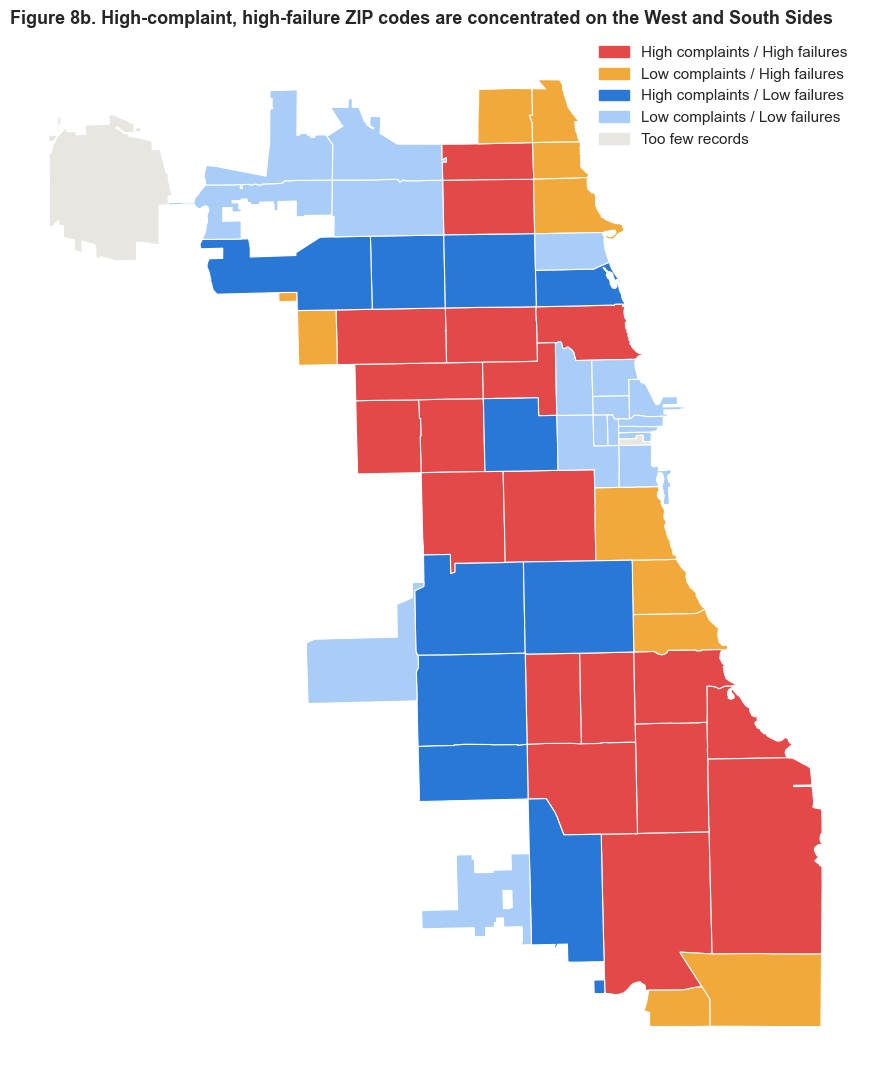

Mapped 57 of 57 analysis ZIPs on 59 city ZIP boundaries.
High complaints / High failures: 60608, 60614, 60617, 60619, 60620, 60621, 60622, 60623, 60624, 60625, 60628, 60636, 60637, 60639, 60644, 60647, 60649, 60651, 60659
Low complaints / High failures: 60615, 60616, 60626, 60633, 60640, 60645, 60653, 60660, 60707, 60827
High complaints / Low failures: 60609, 60612, 60618, 60629, 60632, 60634, 60641, 60643, 60652, 60657
Low complaints / Low failures: 60601, 60602, 60603, 60605, 60606, 60607, 60610, 60611, 60613, 60630, 60631, 60638, 60642, 60646, 60654, 60655, 60656, 60661


In [13]:
import geopandas as gpd
from matplotlib.patches import Patch

# Chicago ZIP boundaries from the city data portal (downloaded once, cached in data/)
boundaries_path = DATA_DIR / "chicago_zip_boundaries.geojson"
if not boundaries_path.exists():
    with urlopen("https://data.cityofchicago.org/resource/unjd-c2ca.geojson?$limit=1000", timeout=120) as response:
        boundaries_path.write_bytes(response.read())
zip_shapes = gpd.read_file(boundaries_path).set_index("zip").join(zip_df["quadrant"])
zip_shapes["quadrant"] = zip_shapes["quadrant"].fillna("Too few records")
map_colors = {**QUADRANT_COLORS, "Too few records": "#e7e6e0"}

fig, ax = plt.subplots(figsize=(9, 11))
for quadrant, color in map_colors.items():
    zip_shapes[zip_shapes["quadrant"] == quadrant].plot(color=color, edgecolor="white", linewidth=0.8, ax=ax)
ax.legend(handles=[Patch(color=color, label=quadrant) for quadrant, color in map_colors.items()],
          loc="upper right")
ax.set_axis_off()
ax.set_title("Figure 8b. High-complaint, high-failure ZIP codes are concentrated on the West and South Sides")
plt.tight_layout()
plt.show()

print(f"Mapped {zip_shapes['quadrant'].ne('Too few records').sum()} of {len(zip_df)} analysis ZIPs "
      f"on {len(zip_shapes)} city ZIP boundaries.")
for quadrant in QUADRANT_COLORS:
    print(f"{quadrant}: {', '.join(sorted(zip_df.index[zip_df['quadrant'] == quadrant]))}")

**Answer: Mostly on the West and South Sides, plus a second group worth watching.** The medians are 235 complaints a year and a 22.8% fail rate.
- **19 ZIPs are high on both** (median 420 complaints a year, 26.5% fail rate, 31.4% pest/garbage citations). Most are on the West Side (60623, 60624, 60644, 60651) and the South Side (60619, 60620, 60628, 60636). They include all eight ZIPs named on the Section 9 priority list.
- **10 ZIPs fail often despite few complaints** (median 158 complaints a year, 24.5% fail rate). These are problems a complaint-based signal would miss. They sit along the North Side lakefront (60626, 60640, 60660) and the mid-South lakefront (60615, 60653), plus border ZIPs such as 60827 and 60633 that lie partly outside 311 coverage.
- **18 ZIPs are low on both**, mainly downtown and on the far Northwest and Southwest Sides.

These are descriptive groups, not risk ratings. A ZIP close to a median line could easily fall in the neighboring group.

## 7. Is the link specific to sanitation? (Figures 9–10)

### 7.1 Are complaints linked to the *sanitation-type* findings in particular?

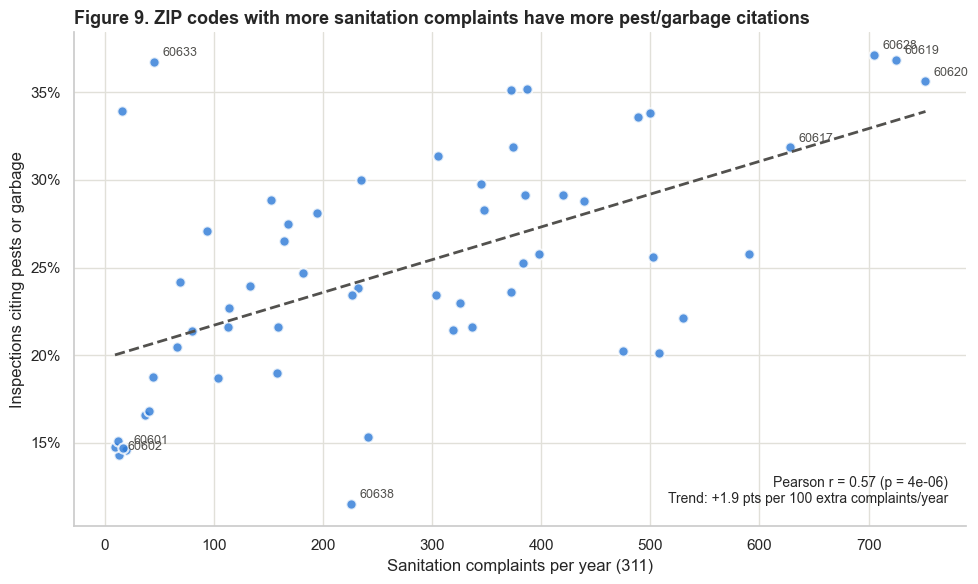

Trend line: 19.8% at zero complaints, +1.87 pts per 100 complaints/year


In [14]:
fit = stats.linregress(zip_df["complaints_per_year"], zip_df["sanitation_violation_rate"])
corr = correlations.loc["sanitation_violation_rate"]

fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=zip_df, x="complaints_per_year", y="sanitation_violation_rate", ci=None, color=BLUE,
            scatter_kws={"s": 55, "edgecolor": "white", "linewidths": 1.5},
            line_kws={"color": GRAY, "linestyle": "--", "linewidth": 2}, ax=ax)

# Label the busiest ZIPs and the ZIPs with the highest and lowest citation rates
labeled = (set(zip_df.nlargest(4, "complaints_per_year").index)
           | set(zip_df.nlargest(3, "sanitation_violation_rate").index)
           | set(zip_df.nsmallest(3, "sanitation_violation_rate").index))
for z in labeled:
    ax.annotate(z, (zip_df.loc[z, "complaints_per_year"], zip_df.loc[z, "sanitation_violation_rate"]),
                xytext=(6, 4), textcoords="offset points", fontsize=9, color=GRAY)

ax.text(0.98, 0.04,
        f"Pearson r = {corr['Pearson r']:.2f} (p = {corr['Pearson p']:.0e})\n"
        f"Trend: +{fit.slope * 100 * 100:.1f} pts per 100 extra complaints/year",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=10)
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(xlabel="Sanitation complaints per year (311)", ylabel="Inspections citing pests or garbage",
       title="Figure 9. ZIP codes with more sanitation complaints have more pest/garbage citations")
plt.tight_layout()
plt.show()

print(f"Trend line: {fit.intercept:.1%} at zero complaints, +{fit.slope * 100 * 100:.2f} pts per 100 complaints/year")

**Answer: Yes, and the effect is larger than for overall failure.** The share of inspections citing pests or garbage has nearly the same correlation with complaints (r = 0.57) as the fail rate does. Its slope is about 60% steeper, though: **+1.9 points per 100 complaints a year**, vs. +1.2 for the fail rate. This is the most direct overlap between the datasets, since both describe pests and refuse.

### 7.2 Which specific violations differ most between high- and low-complaint ZIPs?

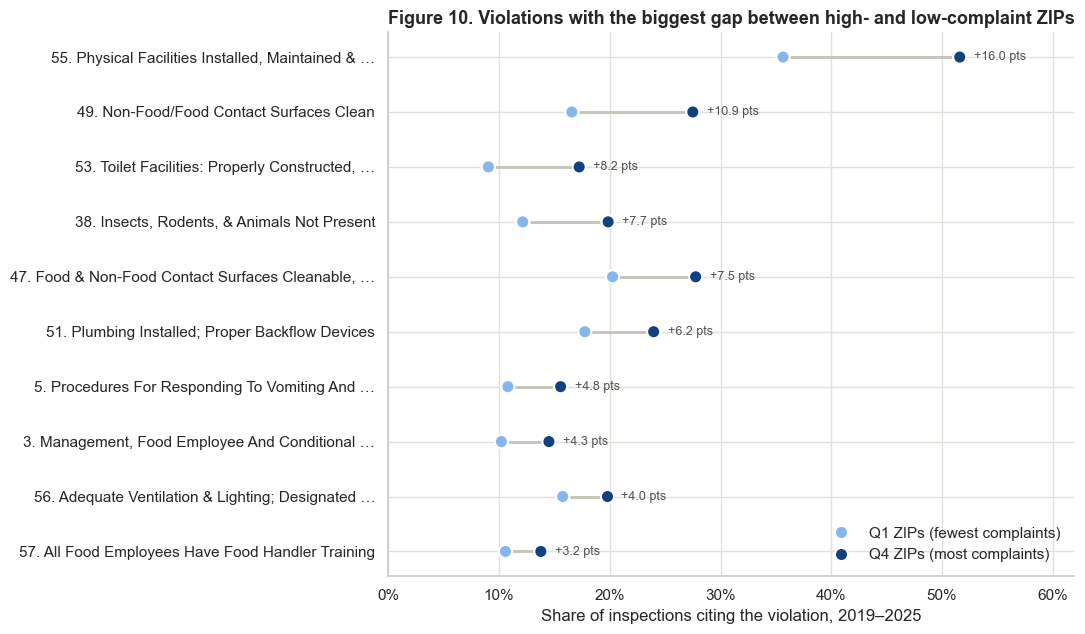

Inspections compared: Q1 = 18,938, Q4 = 33,058


In [15]:
# Split each inspection's violation list into (code, title) pairs. Codes were renumbered with
# the July 2018 food code, so only 2019–2025 inspections are compared here.
recent = inspections[inspections["Year"].between(2019, 2025) & inspections["quartile"].isin(["Q1", "Q4"])]
violations = (recent[["Inspection ID", "quartile", "Violations"]]
              .dropna(subset=["Violations"])
              .assign(segment=lambda d: d["Violations"].str.split("|"))
              .explode("segment"))
violations[["code", "title"]] = violations["segment"].str.extract(r"^\s*(\d+)\.\s*(.*?)\s*(?:- Comments:|$)")
violations = violations.dropna(subset=["code"]).drop_duplicates(["Inspection ID", "code"])

# Share of inspections in each group that cite each code
inspections_per_group = recent.groupby("quartile", observed=True).size()[["Q1", "Q4"]]
share = (violations.groupby(["code", "quartile"], observed=True).size().unstack(fill_value=0)
         [["Q1", "Q4"]].div(inspections_per_group))
share["gap"] = share["Q4"] - share["Q1"]
titles = violations.groupby("code")["title"].first()
share["label"] = (share.index + ". " + titles.reindex(share.index).str.title()).map(
    lambda text: textwrap.shorten(text, width=52, placeholder=" …"))
top_gaps = share[share[["Q1", "Q4"]].max(axis=1) >= 0.05].nlargest(10, "gap")

dots = top_gaps.melt(id_vars="label", value_vars=["Q1", "Q4"], var_name="ZIP group", value_name="share")
dots["ZIP group"] = dots["ZIP group"].map({"Q1": "Q1 ZIPs (fewest complaints)", "Q4": "Q4 ZIPs (most complaints)"})

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.hlines(top_gaps["label"], top_gaps["Q1"], top_gaps["Q4"], color=LIGHT_GRAY, linewidth=2)
sns.scatterplot(data=dots, x="share", y="label", hue="ZIP group", s=90, edgecolor="white", linewidth=1.5,
                palette={"Q1 ZIPs (fewest complaints)": QUARTILE_PALETTE["Q1"],
                         "Q4 ZIPs (most complaints)": QUARTILE_PALETTE["Q4"]},
                zorder=3, ax=ax)
for position, (q4, gap) in enumerate(zip(top_gaps["Q4"], top_gaps["gap"])):
    ax.annotate(f"+{gap * 100:.1f} pts", (q4, position), xytext=(10, 0), textcoords="offset points",
                va="center", fontsize=9, color=GRAY)
ax.set_xlim(0, top_gaps["Q4"].max() * 1.2)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(loc="lower right", title=None)
ax.set(xlabel="Share of inspections citing the violation, 2019–2025", ylabel=None,
       title="Figure 10. Violations with the biggest gap between high- and low-complaint ZIPs")
plt.tight_layout()
plt.show()

print(f"Inspections compared: Q1 = {inspections_per_group['Q1']:,}, Q4 = {inspections_per_group['Q4']:,}")

**Answer: Building condition and cleanliness, not food handling.** We compared 2019–2025 inspections in the highest-complaint quartile (Q4, 33,058 inspections) with the lowest (Q1, 18,938). The biggest gaps were:
- **#55 physical facilities maintained and clean:** +16.0 pts
- **#49 food and non-food contact surfaces clean:** +10.9
- **#53 toilet facilities:** +8.2
- **#38 insects, rodents and animals:** +7.7
- **#47 cleanable surfaces:** +7.5
- **#51 plumbing:** +6.2

Food-handling items such as #3 (management and employee health) and #5 (vomiting/diarrhea procedures) show smaller gaps of about 4 to 5 pts. This points to the physical environment, such as building age, pests and waste handling, which establishments share with the blocks around them.

## 8. Does it survive robustness checks? (Figures 11–14)

### 8.1 Is the gap just a difference in risk mix?

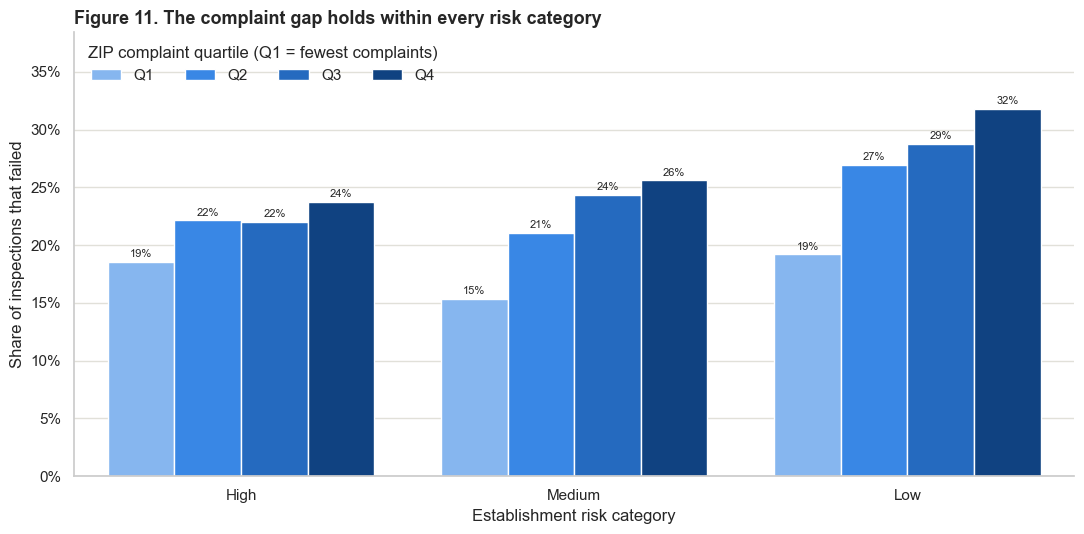

risk,High,Medium,Low
quartile,,,
Q1,0.817,0.146,0.037
Q2,0.791,0.155,0.054
Q3,0.749,0.186,0.065
Q4,0.734,0.190,0.077


In [16]:
in_quartiles = inspections.dropna(subset=["quartile"])

# seaborn averages the 0/1 "failed" column for each risk category and quartile
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(data=in_quartiles, x="risk", y="failed", hue="quartile", order=["High", "Medium", "Low"],
            hue_order=list(QUARTILE_PALETTE), palette=QUARTILE_PALETTE, errorbar=None, saturation=1, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="{:.0%}", padding=2, fontsize=8)
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(title="ZIP complaint quartile (Q1 = fewest complaints)", ncols=4, loc="upper left")
ax.set(xlabel="Establishment risk category", ylabel="Share of inspections that failed",
       title="Figure 11. The complaint gap holds within every risk category")
plt.tight_layout()
plt.show()

# Is the gap a risk-mix effect? Share of each risk category per quartile:
display(pd.crosstab(in_quartiles["quartile"], in_quartiles["risk"], normalize="index")
        [["High", "Medium", "Low"]].round(3))

**Answer: No.** High-complaint ZIPs do have a different mix: 73% of their inspections are *High*-risk vs. 82% in low-complaint ZIPs, with more *Low*-risk establishments, which fail more often (Figure 5). But the gap appears **within every risk category**:
- *High*: 19% → 24%
- *Medium*: 15% → 26%
- *Low*: 19% → 32%

Risk mix does not explain it away.

### 8.2 Is it because high-complaint ZIPs get more complaint-driven inspections?

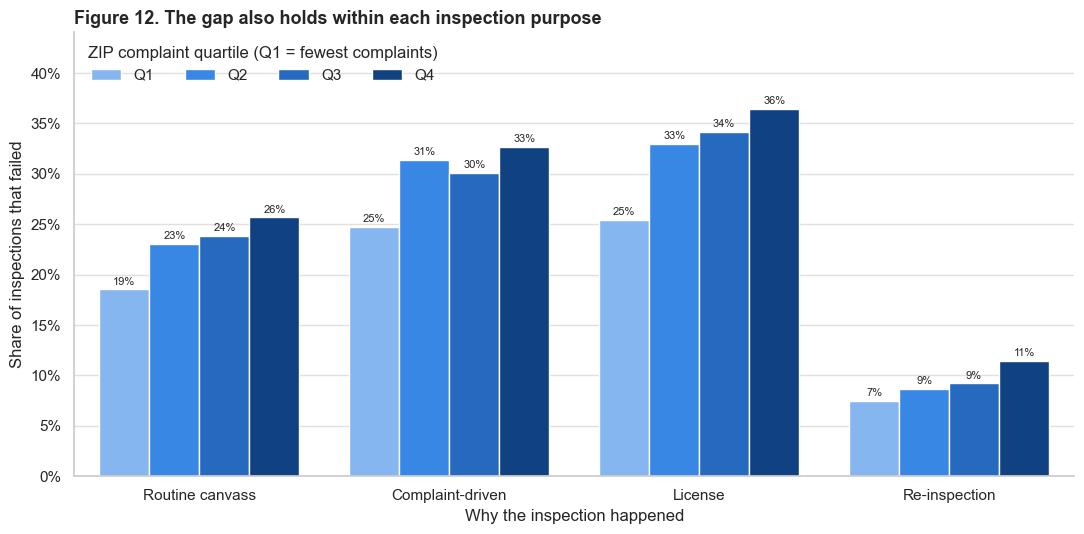

purpose,Routine canvass,Complaint-driven,License,Re-inspection,Other
quartile,,,,,
Q1,0.542,0.121,0.135,0.190,0.012
Q2,0.501,0.141,0.124,0.224,0.011
Q3,0.486,0.136,0.145,0.226,0.008
Q4,0.456,0.145,0.146,0.245,0.008


In [17]:
PURPOSE_ORDER = ["Routine canvass", "Complaint-driven", "License", "Re-inspection"]

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(data=in_quartiles, x="purpose", y="failed", hue="quartile", order=PURPOSE_ORDER,
            hue_order=list(QUARTILE_PALETTE), palette=QUARTILE_PALETTE, errorbar=None, saturation=1, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="{:.0%}", padding=2, fontsize=8)
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(title="ZIP complaint quartile (Q1 = fewest complaints)", ncols=4, loc="upper left")
ax.set(xlabel="Why the inspection happened", ylabel="Share of inspections that failed",
       title="Figure 12. The gap also holds within each inspection purpose")
plt.tight_layout()
plt.show()

# Inspection mix per quartile: do high-complaint ZIPs simply get more complaint-driven visits?
display(pd.crosstab(in_quartiles["quartile"], in_quartiles["purpose"], normalize="index")
        [PURPOSE_ORDER + ["Other"]].round(3))

**Answer: No.** If high-complaint ZIPs simply received more complaint-triggered visits, which fail more, the gap could be an artifact of inspection purpose. But the mix barely differs: complaint-driven visits are 14.5% of inspections in Q4 vs. 12.1% in Q1. Q4 also has *more* re-inspections (24.5% vs. 19.0%), which rarely fail and would *shrink* the gap.

Within each purpose, the gradient holds:
- **Routine canvass:** 19% → 26%. These are not triggered by any complaint, so this is the cleanest comparison.
- **License inspections:** 25% → 36%.

### 8.3 Has the relationship held every year?

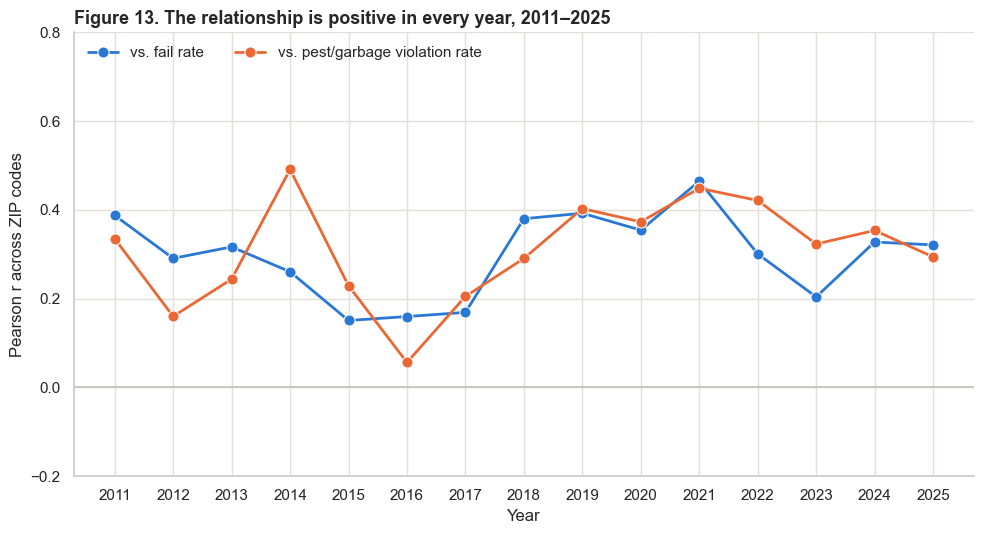

                                  min  mean   max
Correlation                                      
vs. fail rate                    0.15  0.30  0.46
vs. pest/garbage violation rate  0.06  0.31  0.49


In [18]:
# One row per ZIP and year, for ZIP-years with at least 20 inspections
zip_year = (inspections.groupby(["zip", "Year"])
            .agg(n=("Inspection ID", "size"), fail_rate=("failed", "mean"),
                 sanitation_violation_rate=("sanitation_violation", "mean"))
            .join(complaints.groupby(["zip", "Year"]).size().rename("complaints"), how="inner")
            .reset_index())
zip_year = zip_year[(zip_year["n"] >= 20) & zip_year["zip"].isin(zip_df.index)]

# Re-run the ZIP-level correlation separately for each year
rows = []
for year, group in zip_year.groupby("Year"):
    rows.append({
        "Year": year,
        "vs. fail rate": stats.pearsonr(group["complaints"], group["fail_rate"])[0],
        "vs. pest/garbage violation rate": stats.pearsonr(group["complaints"], group["sanitation_violation_rate"])[0],
    })
yearly_r = pd.DataFrame(rows).melt(id_vars="Year", var_name="Correlation", value_name="Pearson r")

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.lineplot(data=yearly_r, x="Year", y="Pearson r", hue="Correlation", palette=[BLUE, ORANGE],
             marker="o", markersize=8, linewidth=2, ax=ax)
ax.axhline(0, color=LIGHT_GRAY, linewidth=1.2)
ax.set_xticks(list(YEARS))
ax.set_ylim(-0.2, 0.8)
ax.legend(loc="upper left", ncols=2, title=None)
ax.set(xlabel="Year", ylabel="Pearson r across ZIP codes",
       title="Figure 13. The relationship is positive in every year, 2011–2025")
plt.tight_layout()
plt.show()

print(yearly_r.groupby("Correlation")["Pearson r"].agg(["min", "mean", "max"]).round(2))

**Answer: Yes.** Re-running the ZIP-level correlation separately for each year gives a positive r in **all 15 years**: 0.15 to 0.46 for the fail rate (mean 0.30) and 0.06 to 0.49 for pest/garbage citations (mean 0.31). Single-year correlations are weaker than the pooled r = 0.56 because one year of inspections per ZIP is a noisier sample, but the sign never flips. The finding does not depend on the period chosen.

### 8.4 Within a ZIP, are high-complaint years also high-failure years?

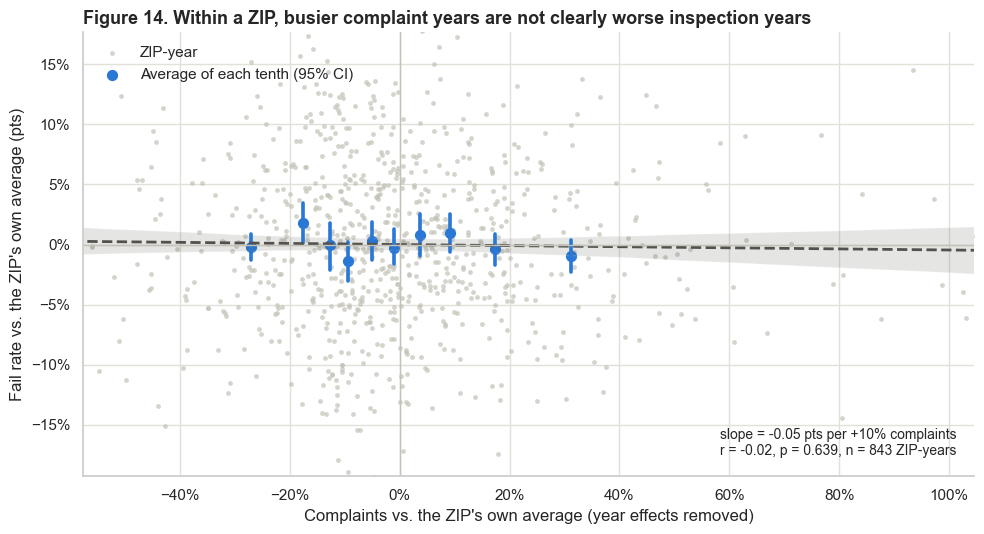

In [19]:
# Within-ZIP test: compare each ZIP-year to that ZIP's own average, then remove citywide
# year effects. If complaints and failures rise and fall together, a ZIP's unusually
# high-complaint years should also be its unusually high-failure years.
panel = zip_year.copy()
panel["complaints_vs_usual"] = panel["complaints"] / panel.groupby("zip")["complaints"].transform("mean") - 1
panel["fail_vs_usual"] = panel["fail_rate"] - panel.groupby("zip")["fail_rate"].transform("mean")
for column in ["complaints_vs_usual", "fail_vs_usual"]:
    panel[column] -= panel.groupby("Year")[column].transform("mean")
fit = stats.linregress(panel["complaints_vs_usual"], panel["fail_vs_usual"])

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.scatterplot(data=panel, x="complaints_vs_usual", y="fail_vs_usual", color=LIGHT_GRAY, s=12,
                linewidth=0, alpha=0.7, label="ZIP-year", ax=ax)
sns.regplot(data=panel, x="complaints_vs_usual", y="fail_vs_usual", x_bins=10, color=BLUE,
            line_kws={"color": GRAY, "linestyle": "--", "linewidth": 2},
            label="Average of each tenth (95% CI)", ax=ax)
ax.axhline(0, color=LIGHT_GRAY, linewidth=1)
ax.axvline(0, color=LIGHT_GRAY, linewidth=1)
ax.set_xlim(panel["complaints_vs_usual"].quantile([0.005, 0.995]))
ax.set_ylim(panel["fail_vs_usual"].quantile([0.005, 0.995]))
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.text(0.98, 0.04, f"slope = {fit.slope * 0.10 * 100:+.2f} pts per +10% complaints\n"
                    f"r = {fit.rvalue:.2f}, p = {fit.pvalue:.3f}, n = {len(panel):,} ZIP-years",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=10)
ax.legend(loc="upper left")
ax.set(xlabel="Complaints vs. the ZIP's own average (year effects removed)",
       ylabel="Fail rate vs. the ZIP's own average (pts)",
       title="Figure 14. Within a ZIP, busier complaint years are not clearly worse inspection years")
plt.tight_layout()
plt.show()

**Answer: No, and this is an important limit.** We compared each ZIP to its own 15-year average and removed citywide year effects. Across 843 ZIP-years, a year with 10% more complaints than usual comes with essentially no change in fail rate: −0.05 pts, r = −0.02, p = 0.64.

**The relationship is between places, not over time.** Lasting neighborhood conditions likely drive both measures, such as older buildings, density, income and commercial mix. Complaint volume is therefore a good guide to *where* to look, but not an early warning of *when* a ZIP is getting worse.

## 9. Where should the city act first? (Figure 15)

### 9.1 Which ZIP codes rank high on all three measures?
We score each ZIP by its average percentile rank on complaints per year, fail rate, and pest/garbage citation rate. A score of 1.0 means worst on all three.

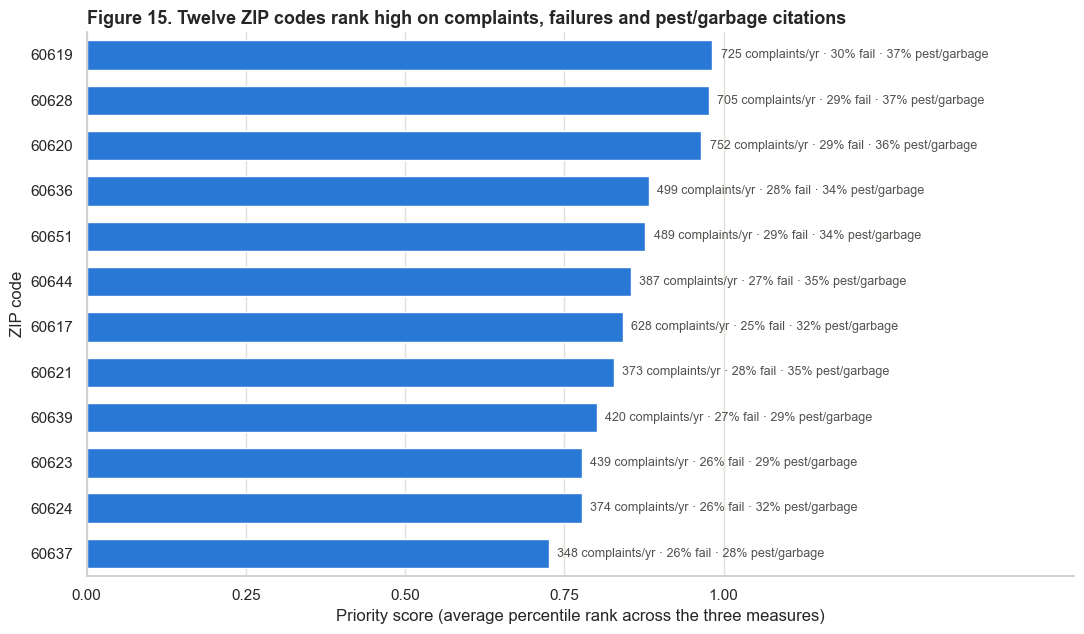

These 12 ZIPs: 39% of complaints, 20% of inspections, fail rate 27.6% vs. 22.4% across all 57 ZIPs.


In [20]:
# Priority score = average percentile rank on the three ZIP measures (1.0 = worst on all three)
measures = ["complaints_per_year", "fail_rate", "sanitation_violation_rate"]
zip_df["priority_score"] = zip_df[measures].rank(pct=True).mean(axis=1)
priority = zip_df.nlargest(12, "priority_score")

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.barplot(x=priority["priority_score"], y=priority.index, color=BLUE, width=0.65, saturation=1, ax=ax)
ax.bar_label(ax.containers[0], padding=6, fontsize=9, color=GRAY, labels=[
    f"{row.complaints_per_year:,.0f} complaints/yr · {row.fail_rate:.0%} fail · {row.sanitation_violation_rate:.0%} pest/garbage"
    for row in priority.itertuples()])
ax.set_xlim(0, 1.55)
ax.set_xticks(np.arange(0, 1.01, 0.25))
ax.set(xlabel="Priority score (average percentile rank across the three measures)", ylabel="ZIP code",
       title="Figure 15. Twelve ZIP codes rank high on complaints, failures and pest/garbage citations")
plt.tight_layout()
plt.show()

print(f"These 12 ZIPs: {priority['complaints'].sum() / zip_df['complaints'].sum():.0%} of complaints, "
      f"{priority['inspections'].sum() / zip_df['inspections'].sum():.0%} of inspections, "
      f"fail rate {np.average(priority['fail_rate'], weights=priority['inspections']):.1%} vs. "
      f"{np.average(zip_df['fail_rate'], weights=zip_df['inspections']):.1%} across all {len(zip_df)} ZIPs.")

**Answer:** Twelve ZIPs stand out, led by **60619, 60628 and 60620**, all of which score above 0.95. Others include 60636, 60651, 60644, 60617 and 60621, mostly on the South and West Sides.

Together these twelve generate **39% of complaints but receive only 20% of inspections**, and they fail **27.6%** of inspections vs. 22.4% across all 57 ZIPs. This is the short list for coordinated action.

## 10. Conclusion and recommendations

**What we found.** Chicago's 311 sanitation complaints and its food-inspection results tell a consistent story at the neighborhood level:
- ZIP codes with more complaints fail more inspections (r = 0.56) and are cited more for pests and garbage (r = 0.57).
- The pattern rises steadily across complaint quartiles (fail rate 18.1% → 24.7%).
- It is driven by building-condition and cleanliness violations.
- It survives controls for risk category and inspection purpose, and it appears in every year from 2011 to 2025.
- It concentrates in a cluster of South and West Side ZIPs that generate 39% of complaints but receive only 20% of inspections.

**What it means.** The within-ZIP test (Figure 14) shows the link reflects *lasting* neighborhood conditions, not short-term co-movement. Complaints are a reliable map of *where* sanitation and food-safety problems coexist, but not an alarm for *when* a ZIP is deteriorating. This is an observational association: it does not show that complaints cause failures, or the reverse.

**Recommendations**
1. **Weight routine canvass scheduling toward the 12 priority ZIPs** (Figure 15). Use multi-year complaint totals, refreshed annually, rather than month-to-month spikes.
2. **Run joint outreach.** CDPH food-safety education on pests, facility cleaning and plumbing (the violations in Figure 10) should be paired with Streets & Sanitation rodent-baiting and cart-replacement programs in the same ZIPs.
3. **Measure the effect.** Pilot the joint program in some priority ZIPs and compare pest/garbage citation rates against similar non-pilot ZIPs, to test whether improving the block improves the kitchen.

**Next steps for the analysis:** add census population and income per ZIP to separate real conditions from reporting behavior, and repeat the analysis at the community-area level once inspections are geocoded to community areas.

## 11. Challenges

| Challenge | How we handled it |
|---|---|
| **The address-level merge failed.** Only ~1% of complaints matched an inspection address, and the many-to-many join duplicated inspection rows. | Replaced it with a concatenation of both sources plus ZIP-level aggregation (Section 4.1). Each inspection and complaint is counted once. |
| **Duplicate complaints:** 7,272 requests marked "Dup" and 807 repeated request numbers. | Dropped them before counting (Section 4.2 audit table). |
| **Non-outcome inspections:** 44,641 results such as *No Entry* or *Out of Business*. | Excluded from fail-rate denominators. |
| **Partial years:** sparse 2010 complaints and incomplete 2026. | Restricted to full years 2011–2025. |
| **Violation codes changed in July 2018.** | Used a keyword flag for pests/garbage across all years, and compared codes only for 2019–2025. |
| **Small ZIPs give noisy rates.** | Required ≥200 inspections and ≥100 complaints. The 57 remaining ZIPs still cover 98% of inspections and 95% of complaints. |
| **Confounding:** risk mix, inspection purpose, time. | Stratified by risk (Fig. 11) and purpose (Fig. 12), repeated by year (Fig. 13), and ran a within-ZIP test (Fig. 14). |
| **No population denominator** in either dataset. | Kept rates on the inspection side and treated complaint volume as a relative signal. Flagged as the main limitation and the first next step. |
| **Border ZIPs** such as 60827 lie partly outside 311 coverage. | Kept them, but called them out as outliers when interpreting Figure 6. |

## 12. References

- City of Chicago, Department of Public Health. [Food Inspections](https://data.cityofchicago.org/Health-Human-Services/Food-Inspections/4ijn-s7e5), Chicago Data Portal. Inspection records; the dataset description documents the July 1, 2018 change to violation definitions.
- City of Chicago. [311 Service Requests: Sanitation Code Complaints (Historical)](https://data.cityofchicago.org/Service-Requests/311-Service-Requests-Sanitation-Code-Complaints-Hi/me59-5fac) and [311 Service Requests](https://data.cityofchicago.org/Service-Requests/311-Service-Requests/v6vf-nfxy), Chicago Data Portal. Complaint records, combined into one extract by the team.
- City of Chicago. [Boundaries - ZIP Codes](https://data.cityofchicago.org/d/unjd-c2ca), Chicago Data Portal. ZIP code polygons used in Figure 8b.
- City of Chicago. [Data Portal Terms of Use](https://www.chicago.gov/city/en/narr/foia/data_disclaimer.html).
- Team 03. [Sanitation-Project repository](https://github.com/idanm-commiting/Sanitation-Project). Source of the five data archives.
- Team 03. `B03-Chicago-Food-Inspection-And-Sanitation.ipynb` (Team Assignment), `ba780_datacleaning.ipynb`, `sanitation_analysis_jason_restored.ipynb` and `chicago_story1_story3_graft.ipynb`. Cleaning rules, the street-map approach, the charts refreshed in Figures 1–5, and the quadrant chart and map adapted in Figures 8a–8b.
- OpenStreetMap contributors. [Map data and tiles](https://www.openstreetmap.org/copyright), used in Figure 3, via [contextily](https://contextily.readthedocs.io/).
- Software documentation: [pandas](https://pandas.pydata.org/docs/), [NumPy](https://numpy.org/doc/), [Matplotlib](https://matplotlib.org/stable/), [seaborn](https://seaborn.pydata.org/), [GeoPandas](https://geopandas.org/), [SciPy `stats`](https://docs.scipy.org/doc/scipy/reference/stats.html) (Pearson correlation, linear regression).
- Course materials: *BA780 Final Project Deliverable & Presentation Rubric*, used for the notebook structure.

## 13. Generative AI disclosure

In completing this project, we used generative AI tools as follows:

- **Analysis design and code (Claude, Anthropic, via Claude Code in VS Code):**
  - Diagnosed why the address-level merge matched only ~1% of complaints and proposed the stack-and-aggregate-to-ZIP approach.
  - Wrote the code for Sections 4 and 6–9 (Figures 6–15), including the correlation tests, quartile and stratified comparisons, the violation-code parser, and the within-ZIP panel test.
  - Restyled the Team Assignment charts (Figures 1–5), then rewrote all 15 charts with seaborn and Matplotlib and simplified the cleaning code at the team's request.
  - Adapted the quadrant chart and ZIP map from the team's Story 3 notebook into Figures 8a–8b, using the report's 57-ZIP data and chart style.
  - Ran the code to check that every number quoted in the text matches the output.
- **Writing (Claude):** drafted the Markdown text: executive summary, introduction, questions and answers, conclusion, challenges, and this statement.
- **Earlier phase (OpenAI Codex):** as disclosed in the Team Assignment, Codex assisted with the cleaning notebook, chart adaptation, and merging the team members' notebooks. Those cleaning rules are reused here.